### Zadania

Główna część listy (zadania 1-3) dotyczy detekcji krawędzi na obrazach. Zadanie 4 kontynuuje temat binaryzacji, skupiając się na operacjach globalnych (przekształceniach histogramu).

In [1]:
import cv2
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

In [2]:
from ipywidgets import interact, IntSlider, FloatSlider, Dropdown, Checkbox, fixed

In [3]:
L = 256
x = np.arange(L)

def show_image(ax, img, title='', cmap='gray'):
    ax.imshow(img, cmap=cmap, vmin=0, vmax=255)
    ax.set_title(title, fontsize=10)
    ax.axis('off')

def hist256(img):
    return np.bincount(img.ravel(), minlength=L)

def cdf_of(img):
    return np.cumsum(hist256(img)) / img.size

def grad_mag(img, ksize=3, sigma=0.0):
    im = img if sigma == 0 else cv2.GaussianBlur(img, (0, 0), sigma)
    gx = cv2.Sobel(im, cv2.CV_64F, 1, 0, ksize=ksize)
    gy = cv2.Sobel(im, cv2.CV_64F, 0, 1, ksize=ksize)
    return np.hypot(gx, gy)

def denoise(img, method='gauss', sigma=2.0, k_med=5):
    if method == 'gauss':
        return cv2.GaussianBlur(img, (0, 0), sigma)
    elif method == 'median':
        return cv2.medianBlur(img, k_med)
    else:
        return img

def pdf_uniform():
    return np.full(L, 1.0 / L)

def pdf_gauss(mu, s):
    p = np.exp(-0.5 * ((x - mu) / s) ** 2)
    return p / p.sum()

def pdf_bimodal(m1, s1, m2, s2, w):
    # 2 górki: ciemna (m1, s1) o wadze 1-w oraz jasna (m2, s2) o wadze w
    return (1 - w) * pdf_gauss(m1, s1) + w * pdf_gauss(m2, s2)

def match_histogram(img, target_pdf):
    cdf_src = cdf_of(img)
    cdf_tgt = np.cumsum(target_pdf)
    cdf_tgt = cdf_tgt / cdf_tgt[-1]
    lut = np.searchsorted(cdf_tgt, cdf_src, side='left')
    lut = np.clip(lut, 0, L - 1).astype(np.uint8)
    return cv2.LUT(img, lut), lut

def otsu(img):
    thr, bw = cv2.threshold(img, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    return thr, bw

##### Zad. 1: Wyznaczenie gradientów

Wykonaj dla obrazu `coins` sztuczny obraz ilustrujący wielkość (moduł) wektora gradientu w danym punkcie. Do wyświetlenia użyj [mapy kolorów](https://matplotlib.org/stable/tutorials/colors/colormaps.html) `hot` do oznaczenia wielkości gradientu odpowiednim kolorem – im większa wartość, tym jaśniej (_mapa ciepła_).  
Gdzie gradienty są bliskie zera?  
Czy uzyskany wynik pozwoliłby np. na detekcję poszczególnych obiektów?

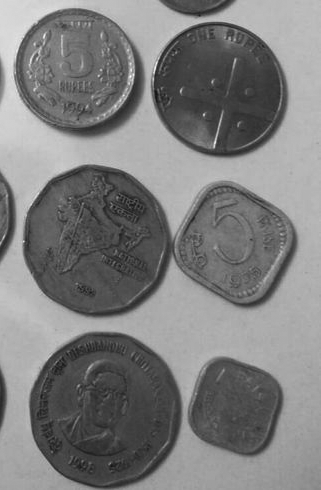

In [5]:
coins = cv2.imread('../lab1/Monety_szare.bmp', cv2.IMREAD_GRAYSCALE)
Image.fromarray(coins)

Rozwiązanie:

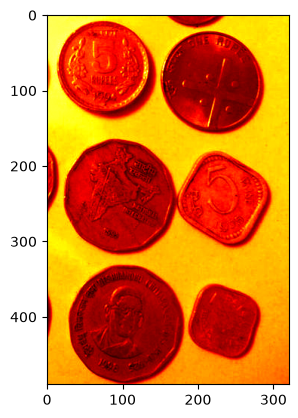

In [6]:
plt.imshow(coins, cmap='hot') # przykład wyświetlania z mapą kolorów

In [84]:
def zad1_explorer(ksize=3, sigma=0.0, T=60):
    mag = grad_mag(coins, ksize, sigma)
    mag_min = mag.min()
    mag_max = mag.max()
    if mag_max > mag_min:
        mag_norm = (mag - mag_min) / (mag_max - mag_min) * 255
    else:
        mag_norm = np.zeros_like(mag)
    print(f'Zakres |G| (bez normalizacji): min={mag_min:.2f}, max={mag_max:.2f}')
    fig, ax = plt.subplots(1, 3, figsize=(16, 5))
    ax[0].imshow(mag, cmap='hot', vmin=0, vmax=255)
    ax[0].set_title('|G|, Sobel ksize=%d, sigma=%.1f' % (ksize, sigma)); ax[0].axis('off')
    ax[1].hist(mag_norm.ravel(), bins=100, log=True)
    ax[1].set_title('Histogram |G| (skala log)'); ax[1].set_xlabel('|G| znormalizowany 0-255')
    ax[2].imshow(mag_norm > T, cmap='gray')
    ax[2].set_title('|G| > %d (znorm.)' % T); ax[2].axis('off')
    plt.show()

Zakres |G| (bez normalizacji): min=0.00, max=217.59


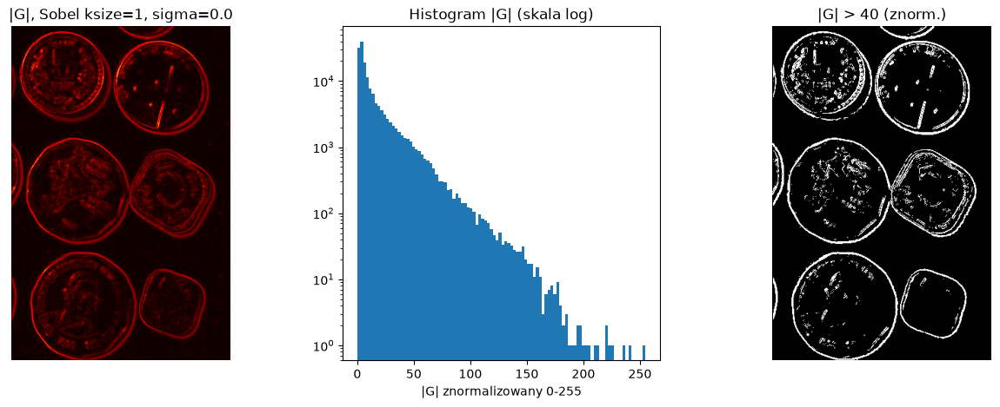

Zakres |G| (bez normalizacji): min=0.00, max=217.59


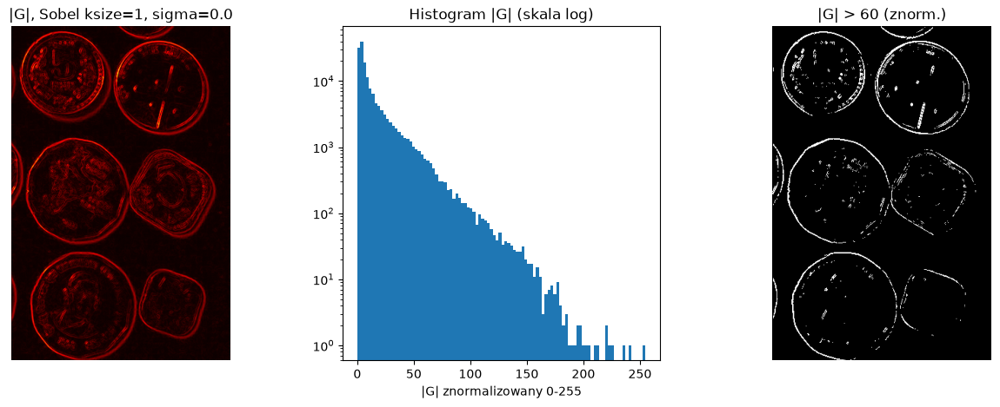

Zakres |G| (bez normalizacji): min=0.00, max=768.73


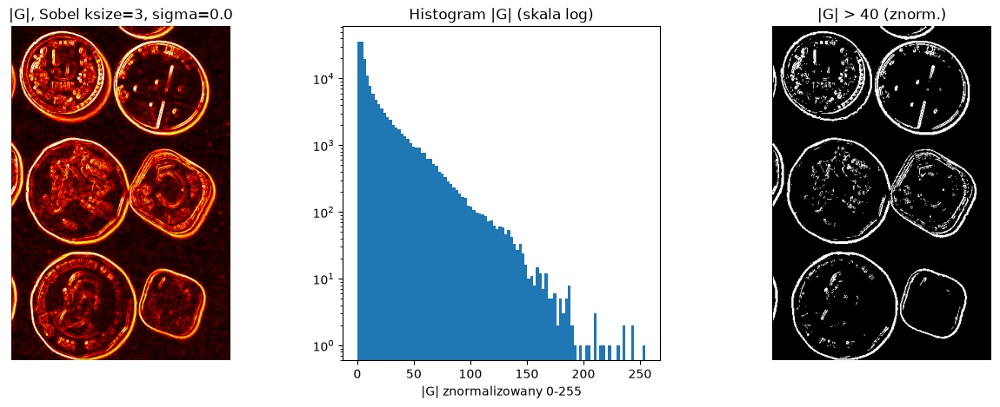

Zakres |G| (bez normalizacji): min=0.00, max=8277.49


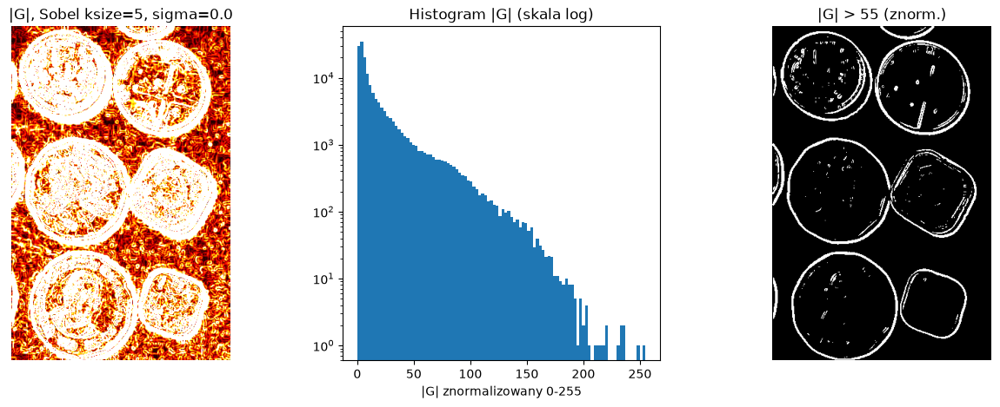

In [85]:
zad1_explorer(ksize=1, sigma=0.0, T=40)
zad1_explorer(ksize=1, sigma=0.0, T=60)
zad1_explorer(ksize=3, sigma=0.0, T=40)
zad1_explorer(ksize=5, sigma=0.0, T=55)

Zakres |G| (bez normalizacji): min=0.00, max=158.40


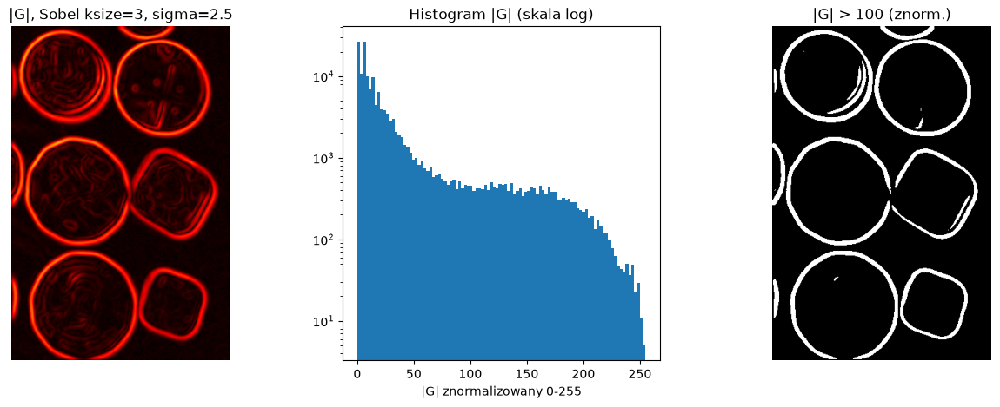

Zakres |G| (bez normalizacji): min=0.00, max=2444.09


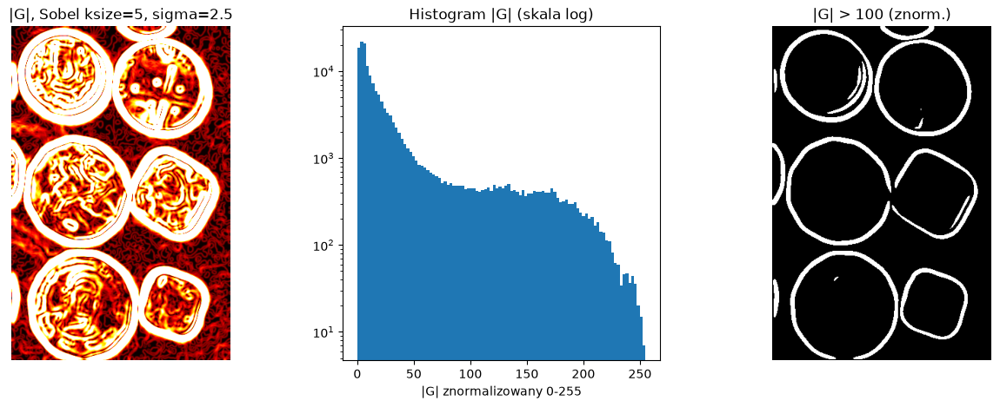

Zakres |G| (bez normalizacji): min=0.00, max=954.87


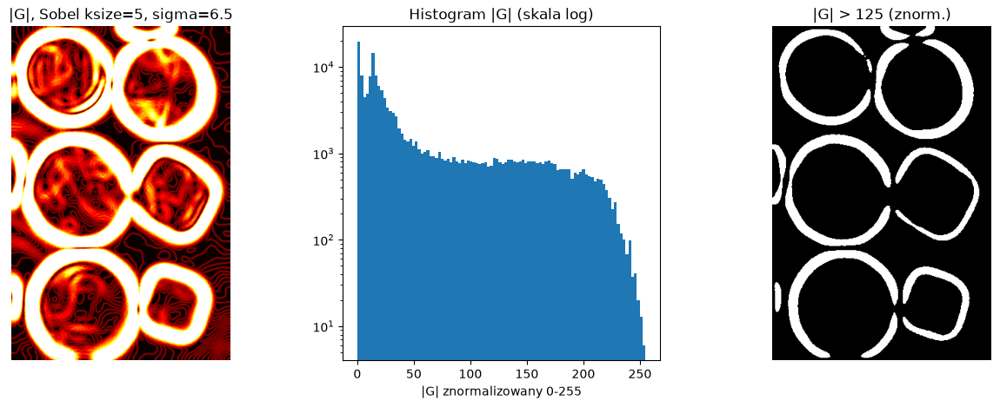

In [86]:
zad1_explorer(ksize=3, sigma=2.5, T=100)
zad1_explorer(ksize=5, sigma=2.5, T=100)
zad1_explorer(ksize=5, sigma=6.5, T=125)

---

##### Zad. 2: Detekcja krawędzi

Przeprowadź z obrazem `coins_noise` takie przekształcenia, aby zmaksymalizować możliwość rozpoznania obiektów. Wykorzystaj [filtr Canny'ego](https://docs.opencv.org/4.x/dd/d1a/group__imgproc__feature.html#ga04723e007ed888ddf11d9ba04e2232de) do detekcji krawędzi; zbadaj jego zachowanie w zależności od wartości **progów** oraz sposobu redukcji **szumu**.

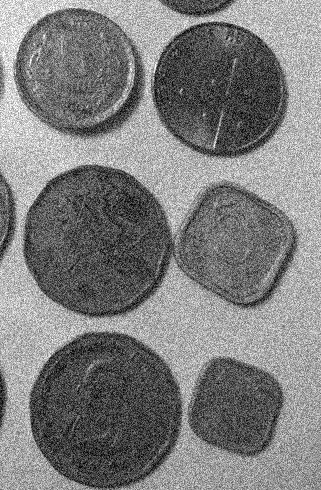

In [14]:
coins_noise = cv2.imread('../lab1/Monety_szare_szum.bmp', cv2.IMREAD_GRAYSCALE)
Image.fromarray(coins_noise)

Rozwiązanie:

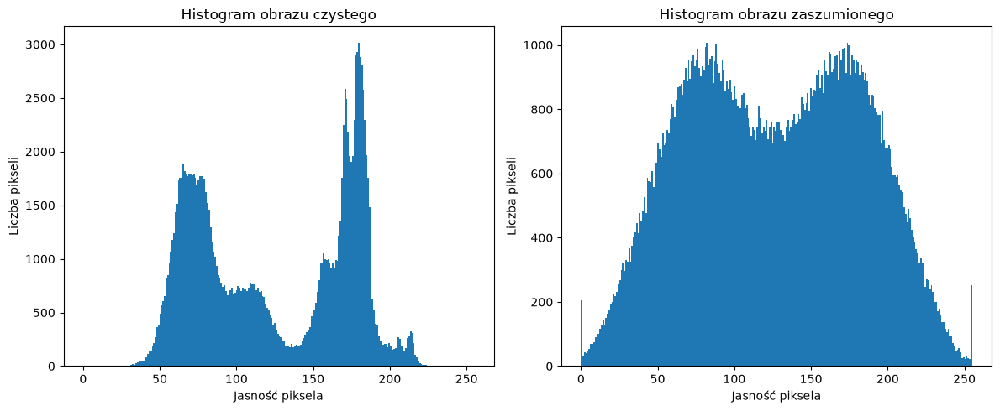

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
ax[0].hist(coins.ravel(), bins=256, range=(0, 255))
ax[0].set_title('Histogram obrazu czystego')
ax[0].set_xlabel('Jasność piksela')
ax[0].set_ylabel('Liczba pikseli')
ax[1].hist(coins_noise.ravel(), bins=256, range=(0, 255))
ax[1].set_title('Histogram obrazu zaszumionego')
ax[1].set_xlabel('Jasność piksela')
ax[1].set_ylabel('Liczba pikseli')
plt.tight_layout()
plt.show()

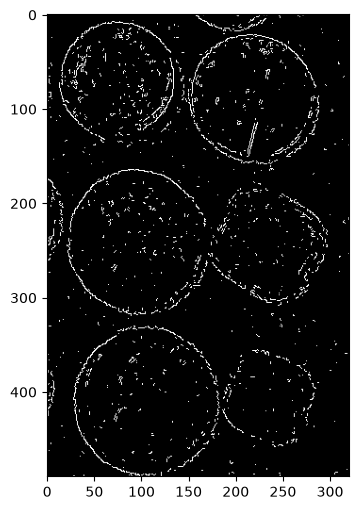

In [17]:
edges = cv2.Canny(coins_noise, 300, 400)
fig = plt.figure(figsize=(6, 6))
plt.imshow(edges, cmap='gray')

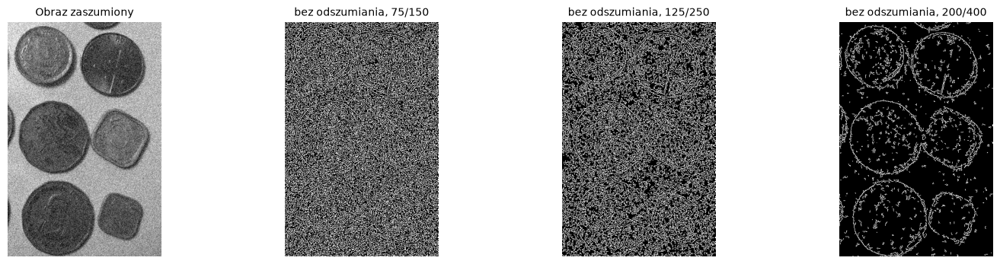

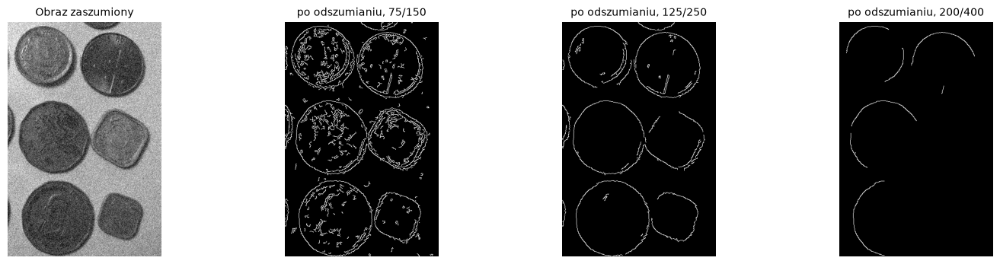

In [ ]:
fig, ax = plt.subplots(1, 4, figsize=(18, 4))
show_image(ax[0], coins_noise, 'Obraz zaszumiony')
for a, hi in zip(ax[1:], (150, 250, 400)):
    e = cv2.Canny(coins_noise, hi // 2, hi)
    show_image(a, e, f'bez odszumiania, {hi // 2}/{hi}')
plt.show()

#denoise
fig, ax = plt.subplots(1, 4, figsize=(18, 4))
show_image(ax[0], coins_noise, 'Obraz zaszumiony')
for a, hi in zip(ax[1:], (150, 250, 400)):
    coins_denoised = cv2.GaussianBlur(coins_noise, (0, 0), 1)
    e = cv2.Canny(coins_denoised, hi // 2, hi)
    show_image(a, e, f'po odszumianiu, {hi // 2}/{hi}')
plt.show()

In [19]:
def zad2_explorer(method='gauss', sigma=2.0, k_med=5, low=35, high=70, aperture=3, L2=False):
    den = denoise(coins_noise, method, sigma, k_med)
    e = cv2.Canny(den, low, high, apertureSize=aperture, L2gradient=L2)
    mask = cv2.cvtColor(coins_noise, cv2.COLOR_GRAY2RGB)
    mask[e > 0] = (255, 0, 0)
    fig, ax = plt.subplots(1, 3, figsize=(16, 5.5))
    show_image(ax[0], den, 'po odszumianiu: ' + method)
    show_image(ax[1], e, 'Canny low=%d high=%d' % (low, high))
    show_image(ax[2], mask, 'Krawędzie na oryginale')
    plt.show()

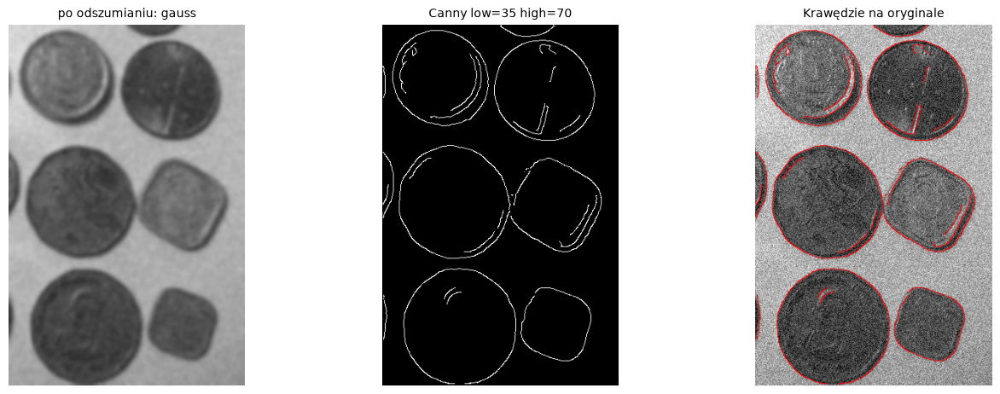

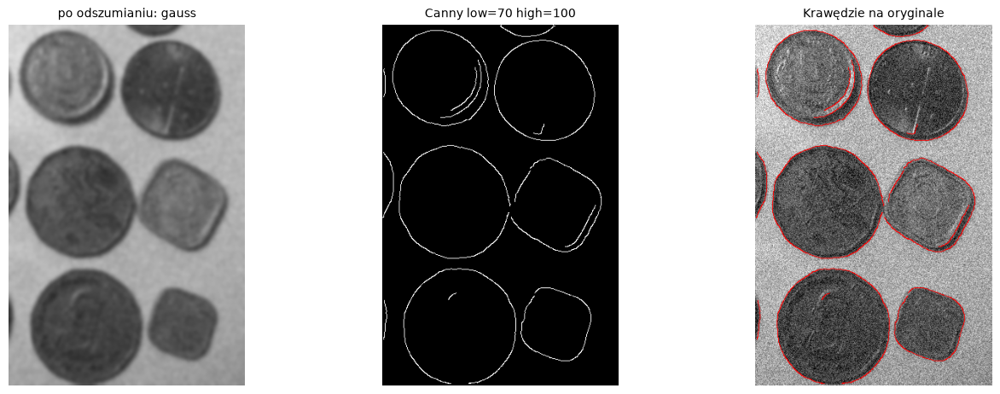

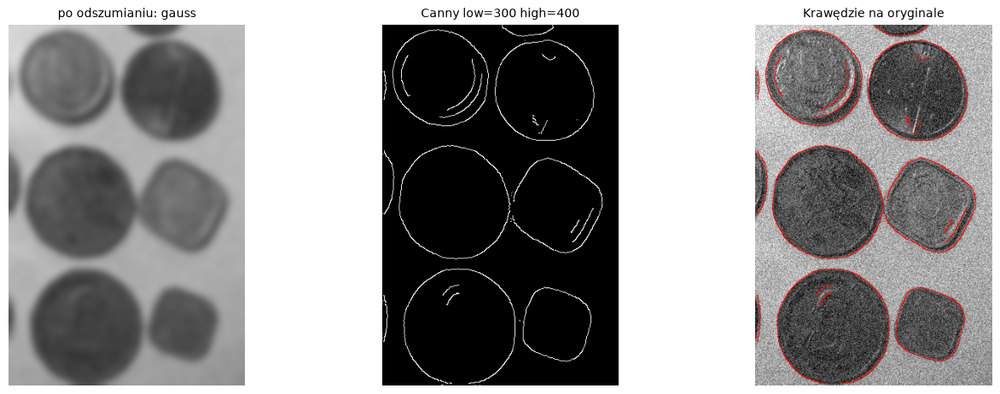

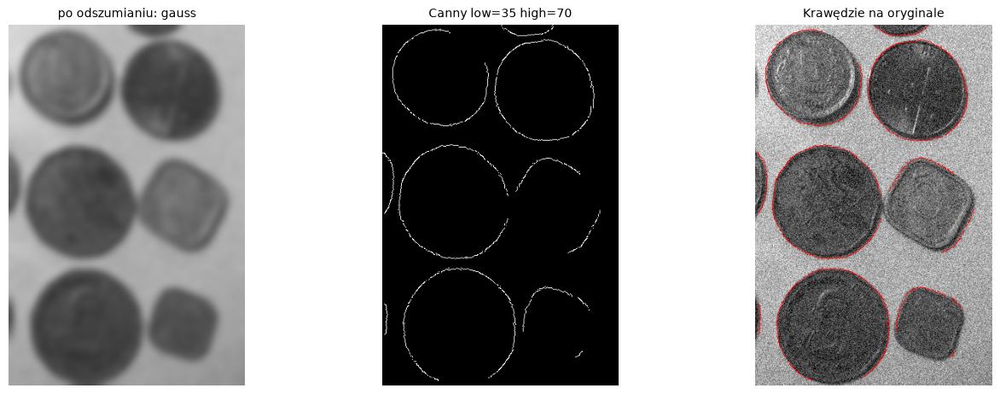

In [91]:
zad2_explorer(method='gauss', sigma=2.5, low=35, high=70)
zad2_explorer(method='gauss', sigma=2.5, low=70, high=100)
zad2_explorer(method='gauss', sigma=5.0, low=300, high=400, aperture=5)
zad2_explorer(method='gauss', sigma=5.0, low=35, high=70)


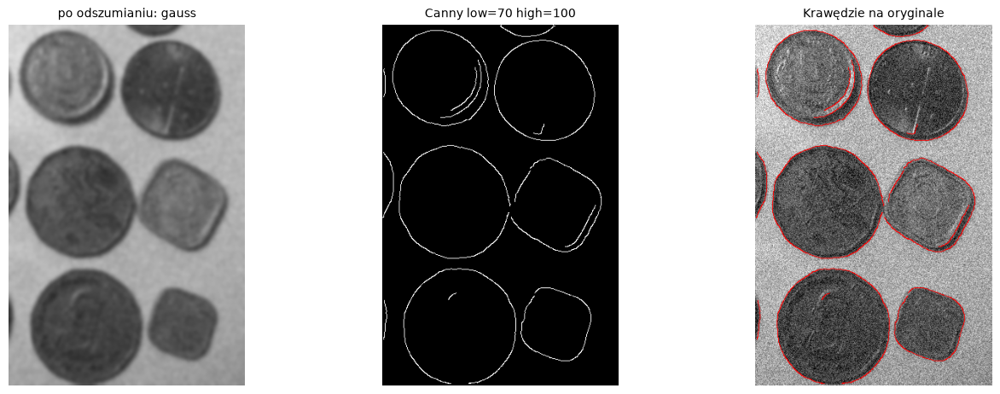

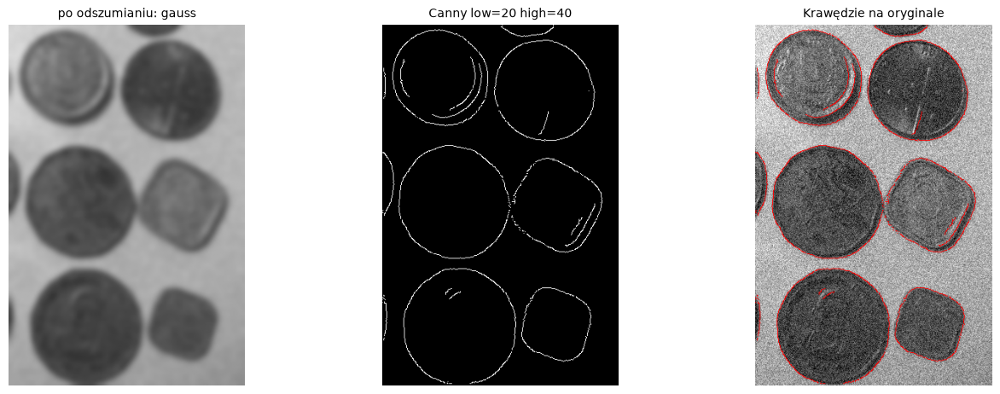

In [73]:
zad2_explorer(method='gauss', sigma=2.5, low=70, high=100)
zad2_explorer(method='gauss', sigma=4, low=20, high=40)


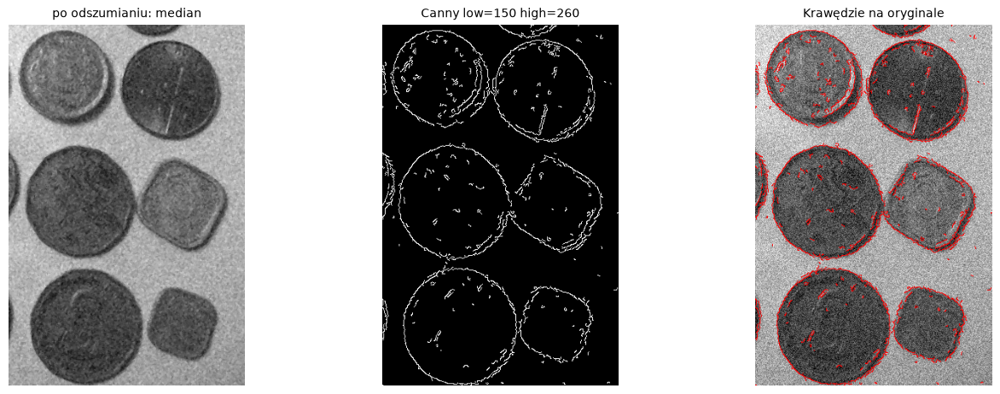

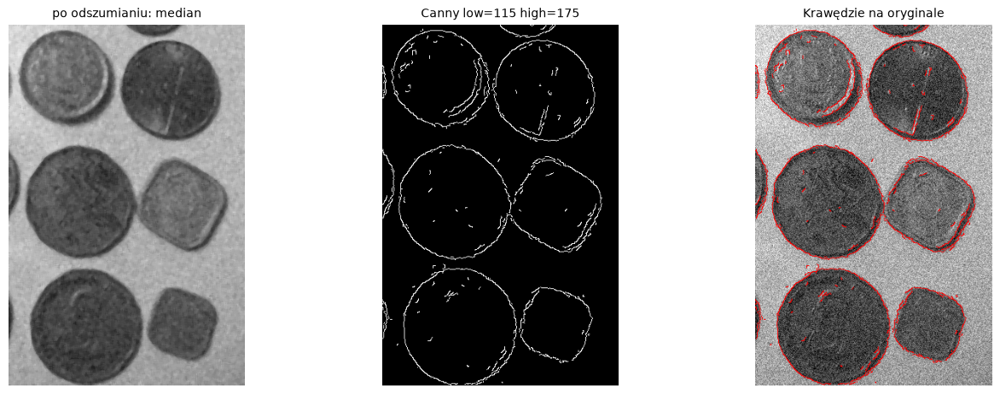

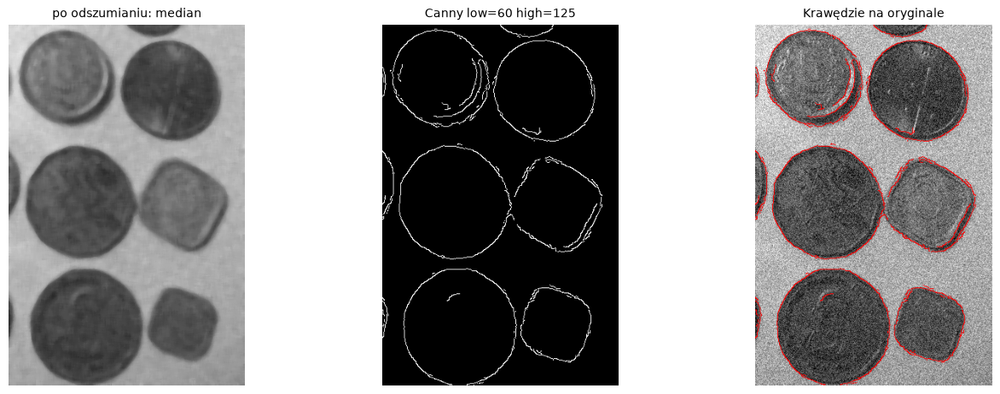

In [22]:
zad2_explorer(method='median', k_med=3, low=150, high=260)
zad2_explorer(method='median', k_med=5, low=115, high=175)
zad2_explorer(method='median', k_med=9, low=60, high=125)




---

##### Zad. 3: Wyrównanie histogramu

Wyrównaj histogram obrazu `coins_noise`. Wyniki zaprezentuj za pomocą obrazów i towarzyszących im histogramów. Powtórz eksperyment z detekcją krawędzi (zad. 2) dla wyrównanego obrazu i omów różnice.

In [23]:
def show_image_with_hist(img, title='', cmap='gray'):
    fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
    show_image(ax[0], img, title)
    ax[1].bar(x, hist256(img), width=1.0); ax[1].set_title('Histogram'); ax[1].set_xlim(-10, 265)
    ax[2].plot(x, cdf_of(img), label='dystrybuanta obrazu')
    ax[2].plot([0, 255], [0, 1], 'r--', label='rozkład jednostajny')
    ax[2].legend(); ax[2].set_title('Dystrybuanta'); ax[2].set_xlim(0, 255)
    plt.show()

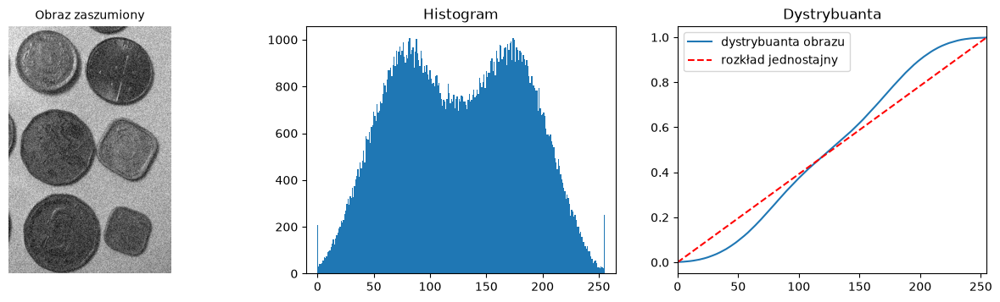

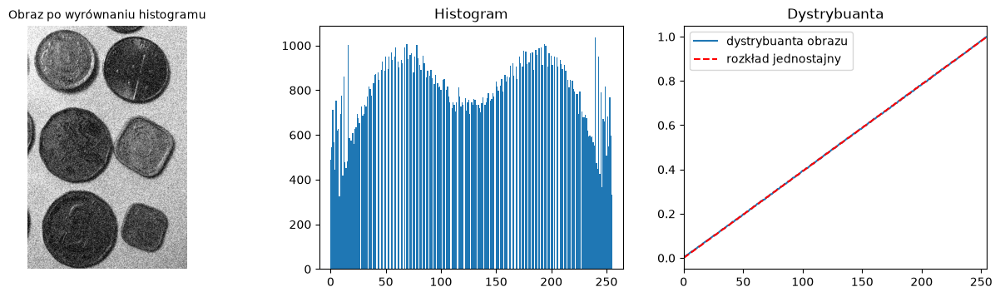

In [24]:
show_image_with_hist(coins_noise, 'Obraz zaszumiony')
equalized_coins_noise = cv2.equalizeHist(coins_noise)
show_image_with_hist(equalized_coins_noise, 'Obraz po wyrównaniu histogramu')

In [92]:
def zad3_explorer(order='equalize,blur', sigma=2.0, low=35, high=70, low2=35, high2=70):
    G = lambda img: cv2.GaussianBlur(img, (0, 0), sigma)
    base = G(coins_noise)
    alt = G(cv2.equalizeHist(coins_noise)) if order == 'equalize,blur' else cv2.equalizeHist(G(coins_noise))
    edges_A = cv2.Canny(base, low, high)
    edges_B = cv2.Canny(alt, low2, high2)
    fig, ax = plt.subplots(2, 2, figsize=(11, 10))
    print(f"A: min |G| = {grad_mag(base, sigma=sigma).min():.2f}, max |G| = {grad_mag(base, sigma=sigma).max():.2f}")
    print(f"B: min |G| = {grad_mag(alt, sigma=sigma).min():.2f}, max |G| = {grad_mag(alt, sigma=sigma).max():.2f}")
    show_image(ax[0, 0], base, 'A: tylko rozmycie')
    show_image(ax[0, 1], edges_A, 'A: Canny %d/%d' % (low, high))
    show_image(ax[1, 0], alt, 'B: ' + order)
    show_image(ax[1, 1], edges_B, 'B: Canny %d/%d' % (low2, high2))
    plt.tight_layout()
    plt.show()

A: min |G| = 0.00, max |G| = 149.41
B: min |G| = 0.00, max |G| = 193.13


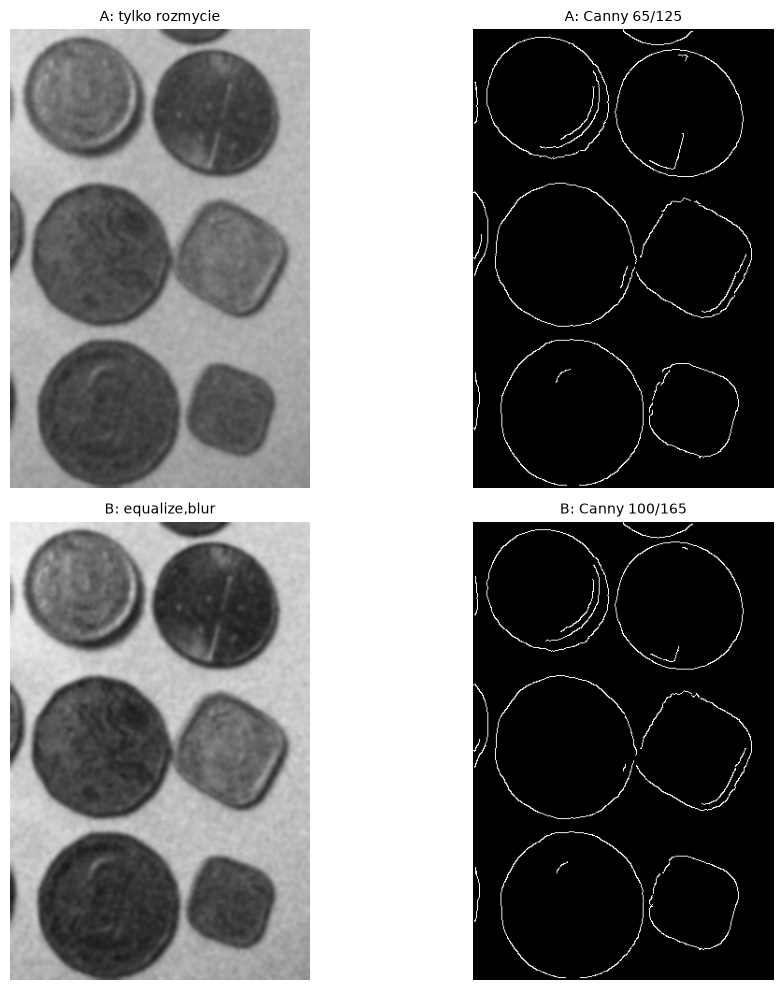

In [93]:
zad3_explorer(order='equalize,blur', sigma=2, low=65, high=125, low2=100, high2=165)

A: min |G| = 0.00, max |G| = 83.57
B: min |G| = 0.00, max |G| = 108.46


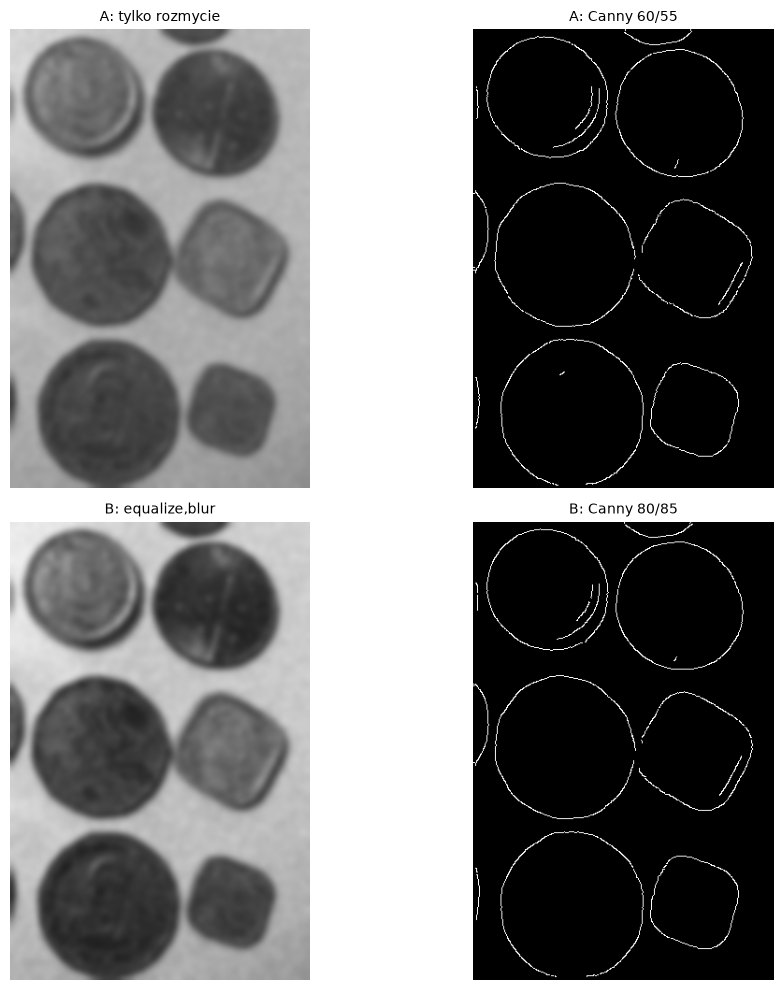

In [94]:
zad3_explorer(order='equalize,blur', sigma=3.5, low=60, high=55, low2=80, high2=85)


A: min |G| = 0.00, max |G| = 174.47
B: min |G| = 0.00, max |G| = 266.18


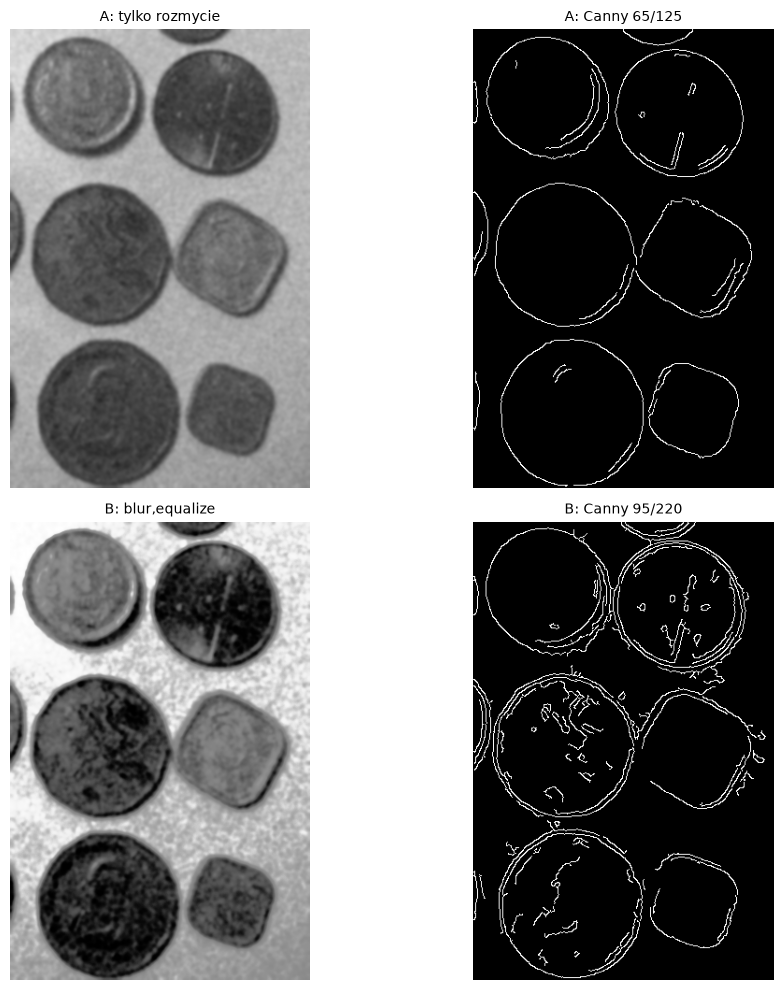

In [95]:
zad3_explorer(order='blur,equalize', sigma=1.75, low=65, high=125, low2=95, high2=220)

---

##### Zad. 4: Transformacja do rozkładu docelowego

Dla obrazów `albatross_single` (od tego zacznij) i `albatross_crowd` wykonaj transformację do wybranego (założonego przez siebie) rozkładu docelowego, tak aby zmaksymalizować możliwość wyodrębnienia obiektów (albatrosów) z otoczenia przy użyciu algorytmu binaryzacji Otsu. Zbadaj wpływ kształtu rozkładu docelowego na zachowanie transformacji.  
Jaki(e) parametr(y) rozkładu są najistotniejsze?

Podpowiedź: przedstawiona we wstępie teoretycznym transformacja obu rozkładów (źródłowego i docelowego) do rozkładu jednostajnego nie musi zostać wykonana _wprost_ (dlatego nie używaj w zadaniu funkcji `cv2.equalizeHist`)! Wystarczy porównywanie ze sobą wartości ze skumulowanych rozkładów (rysunek 3).

Podpowiedź 2: [`cv2.LUT`](https://docs.opencv.org/4.5.3/d2/de8/group__core__array.html#gab55b8d062b7f5587720ede032d34156f)

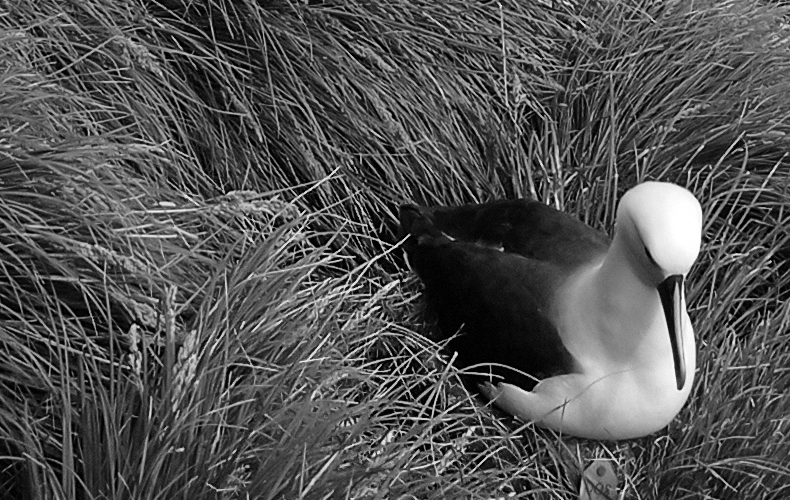

In [30]:
albatross_single = cv2.imread('albatross_single.png', cv2.IMREAD_GRAYSCALE)
Image.fromarray(albatross_single)

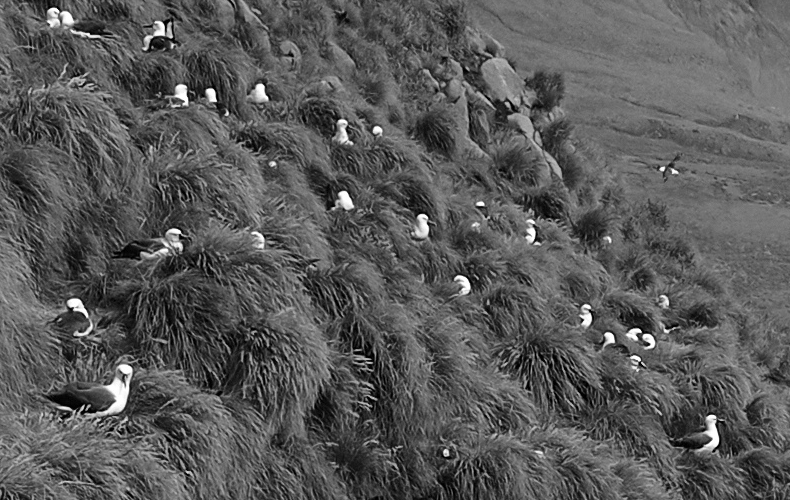

In [31]:
albatross_crowd = cv2.imread('albatross_crowd.png', cv2.IMREAD_GRAYSCALE)
Image.fromarray(albatross_crowd)

Rozwiązanie:

In [32]:
print(albatross_single.shape, albatross_crowd.shape)
print('albatross_single min/max:', albatross_single.min(), albatross_single.max())
print('albatross_crowd min/max:', albatross_crowd.min(), albatross_crowd.max())

(500, 790) (500, 790)
albatross_single min/max: 0 255
albatross_crowd min/max: 0 255


Pojedynczy ptak:

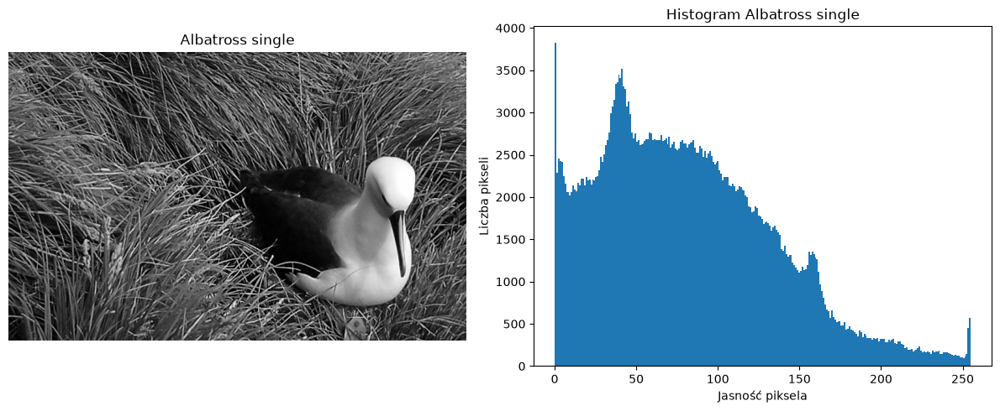

In [33]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
ax[0].imshow(albatross_single, cmap='gray')
ax[0].set_title('Albatross single')
ax[0].axis('off')
ax[1].hist(albatross_single.ravel(), bins=256, range=(0, 255))
ax[1].set_title('Histogram Albatross single')
ax[1].set_xlabel('Jasność piksela')
ax[1].set_ylabel('Liczba pikseli')
plt.tight_layout()
plt.show()

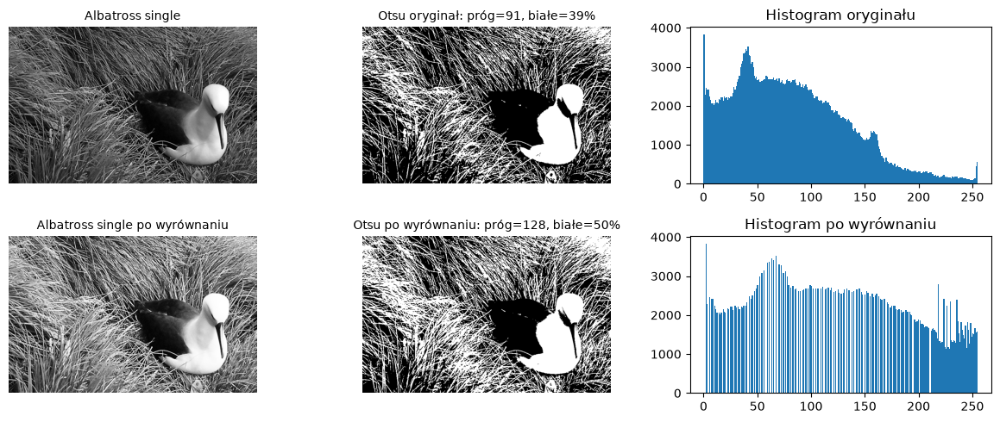

In [34]:
fig, ax = plt.subplots(2, 3, figsize=(12, 5))
thr, binary_img = otsu(albatross_single)
eqm, _ = match_histogram(albatross_single, pdf_uniform())
thr2, binary_img2 = otsu(eqm)
show_image(ax[0,0], albatross_single, 'Albatross single')
show_image(ax[0,1], binary_img, 'Otsu oryginał: próg=%d, białe=%.0f%%' % (thr, 100 * (binary_img > 0).mean()))
ax[0, 2].hist(albatross_single.ravel(), bins=256, range=(0, 255))
ax[0, 2].set_title('Histogram oryginału')
show_image(ax[1,0], eqm, 'Albatross single po wyrównaniu')
show_image(ax[1,1], binary_img2, 'Otsu po wyrównaniu: próg=%d, białe=%.0f%%' % (thr2, 100 * (binary_img2 > 0).mean()))
ax[1, 2].hist(eqm.ravel(), bins=256, range=(0, 255))
ax[1, 2].set_title('Histogram po wyrównaniu')
plt.tight_layout(); plt.show()

In [35]:
def zad4_explorer(obraz='single', ksztalt='dwumodalny', mu=128, s=40, m1=60, s1=20, m2=200, s2=20, w=0.05):
    img = albatross_single if obraz == 'single' else albatross_crowd
    if ksztalt == 'jednostajny':
        tgt = pdf_uniform()
    elif ksztalt == 'jednomodalny':
        tgt = pdf_gauss(mu, s)
    else:
        tgt = pdf_bimodal(m1, s1, m2, s2, w)
    out, _ = match_histogram(img, tgt)
    thr, bw = otsu(out)
    fig, ax = plt.subplots(1, 3, figsize=(18, 5))
    show_image(ax[0], out, 'po transformacji')
    ax[1].bar(x, hist256(out) / out.size, width=1.0); ax[1].plot(x, tgt, 'r'); ax[1].axvline(thr, color='g'); ax[1].set_title('histogram (czerwony = cel, zielony = próg Otsu=%d)' % thr)
    show_image(ax[2], bw, 'Otsu: białe = %.1f%% pikseli' % (100 * (bw > 0).mean()))
    plt.show()

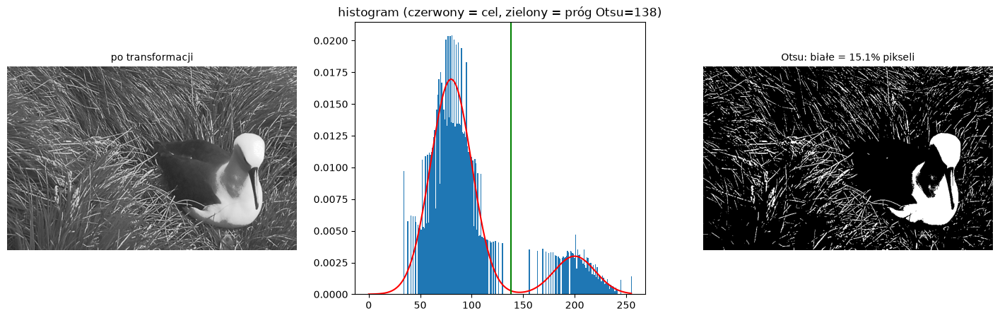

In [47]:
zad4_explorer(obraz='single', ksztalt='dwumodalny', mu=128, s=60, m1=80, s1=20, m2=200, s2=20, w=0.15)

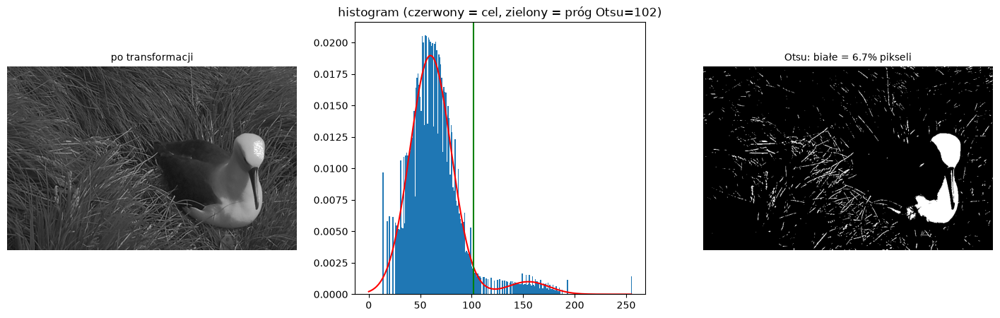

In [46]:
zad4_explorer(obraz='single', ksztalt='dwumodalny', m1=60, s1=20, m2=155, s2=20, w=0.05)

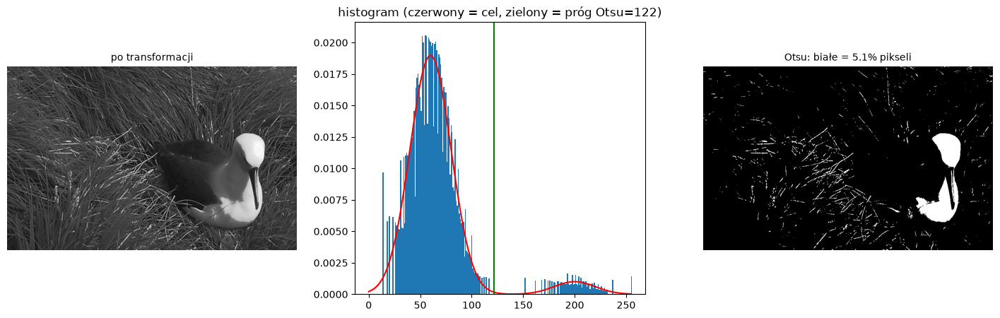

In [ ]:
zad4_explorer(obraz='single', ksztalt='dwumodalny', m1=60, s1=20, m2=200, s2=20, w=0.05)

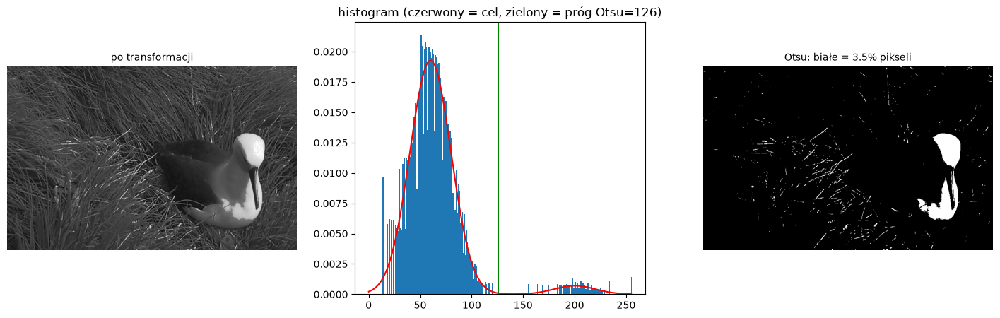

In [41]:
zad4_explorer(obraz='single', ksztalt='dwumodalny', m1=60, s1=20, m2=200, s2=20, w=0.035)


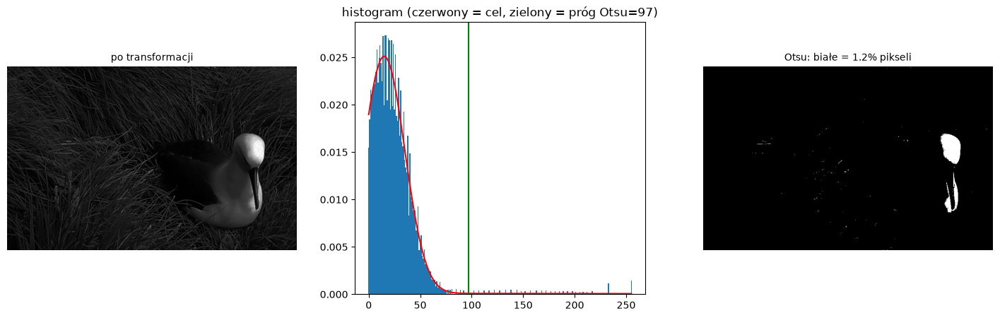

In [ ]:
zad4_explorer(obraz='single', ksztalt='dwumodalny', mu=130, s=40,  m1=15, s1=20, m2=100, s2=200, w=0.02)

Grupa ptaków:

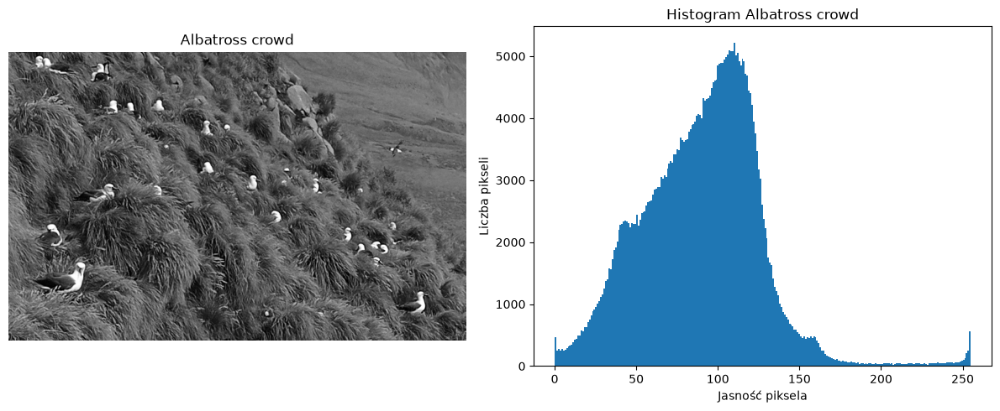

In [53]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
ax[0].imshow(albatross_crowd, cmap='gray')
ax[0].set_title('Albatross crowd')
ax[0].axis('off')
ax[1].hist(albatross_crowd.ravel(), bins=256, range=(0, 255))
ax[1].set_title('Histogram Albatross crowd')
ax[1].set_xlabel('Jasność piksela')
ax[1].set_ylabel('Liczba pikseli')
plt.tight_layout()
plt.show()

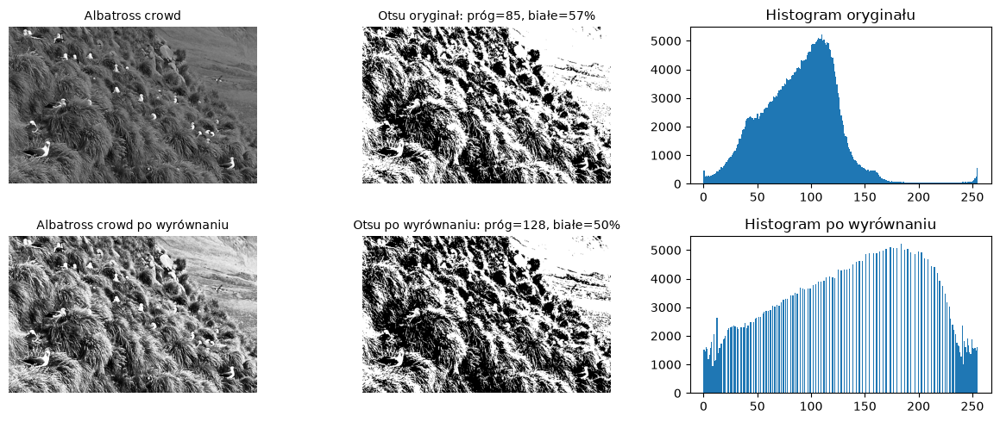

In [54]:
fig, ax = plt.subplots(2, 3, figsize=(12, 5))
thr, binary_img = otsu(albatross_crowd)
eqm, _ = match_histogram(albatross_crowd, pdf_uniform())
thr2, binary_img2 = otsu(eqm)
show_image(ax[0,0], albatross_crowd, 'Albatross crowd')
show_image(ax[0,1], binary_img, 'Otsu oryginał: próg=%d, białe=%.0f%%' % (thr, 100 * (binary_img > 0).mean()))
ax[0, 2].hist(albatross_crowd.ravel(), bins=256, range=(0, 255))
ax[0, 2].set_title('Histogram oryginału')
show_image(ax[1,0], eqm, 'Albatross crowd po wyrównaniu')
show_image(ax[1,1], binary_img2, 'Otsu po wyrównaniu: próg=%d, białe=%.0f%%' % (thr2, 100 * (binary_img2 > 0).mean()))
ax[1, 2].hist(eqm.ravel(), bins=256, range=(0, 255))
ax[1, 2].set_title('Histogram po wyrównaniu')
plt.tight_layout(); plt.show()

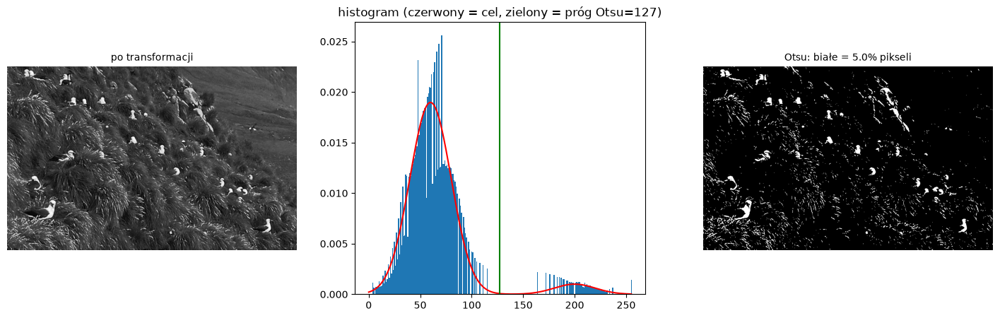

In [55]:
zad4_explorer(obraz='crowd', ksztalt='dwumodalny', m1=60, s1=20, m2=200, s2=20, w=0.05)

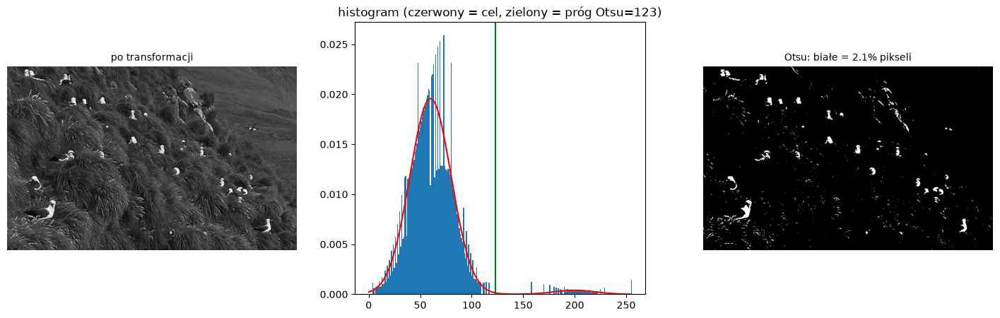

In [57]:
zad4_explorer(obraz='crowd', ksztalt='dwumodalny', m1=60, s1=20, m2=200, s2=20, w=0.02)

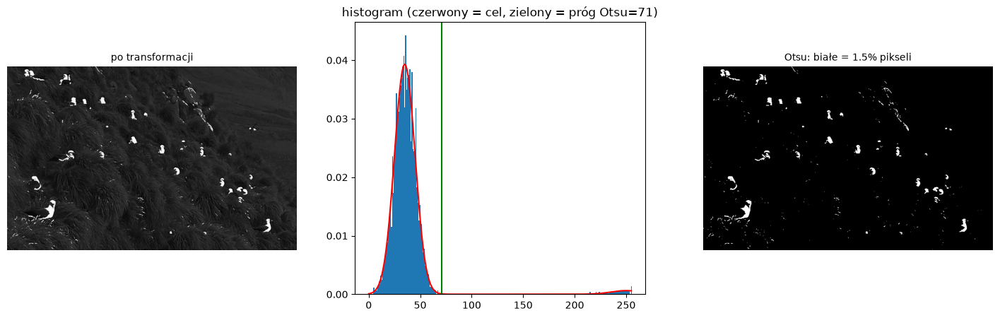

In [ ]:
zad4_explorer(obraz='crowd', ksztalt='dwumodalny', m1=35, s1=10, m2=250, s2=15, w=0.015)

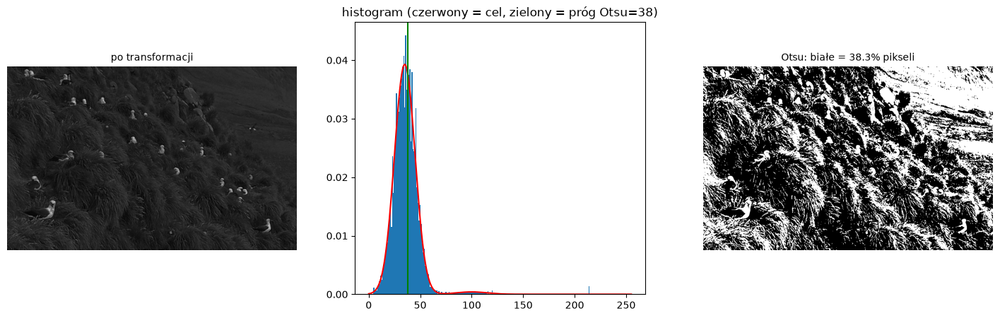

In [67]:
zad4_explorer(obraz='crowd', ksztalt='dwumodalny', m1=35, s1=10, m2=100, s2=15, w=0.015)

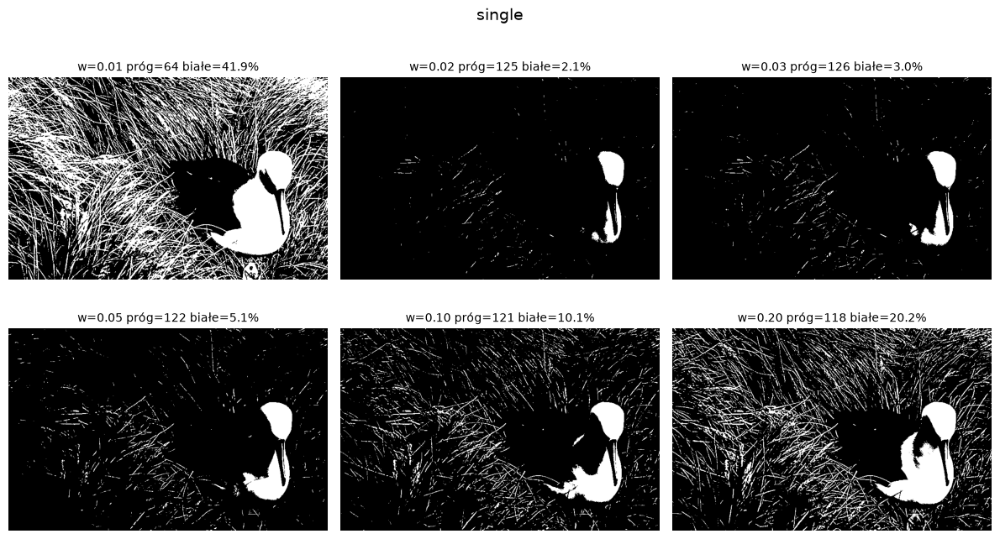

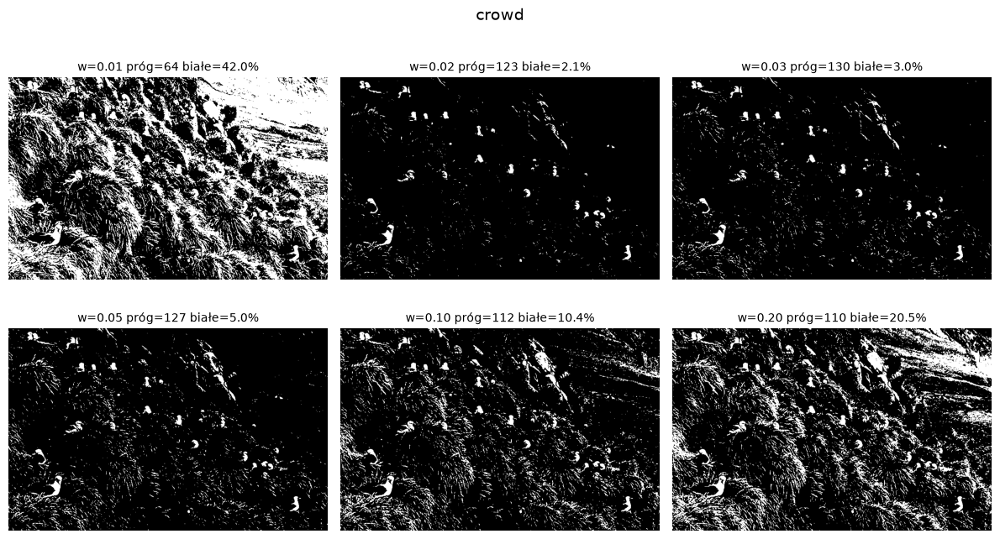

In [70]:
ws = [0.01, 0.02, 0.03, 0.05, 0.10, 0.20]

for name, img in [('single', albatross_single),
                   ('crowd', albatross_crowd)]:
    fig, ax = plt.subplots(2, 3, figsize=(12, 7))
    ax = ax.ravel()
    for a, w in zip(ax, ws):
        out, _ = match_histogram(img, pdf_bimodal(60, 20, 200, 20, w))
        thr, bw = otsu(out)
        show_image(a, bw, 'w=%.2f próg=%d białe=%.1f%%' % (w, thr, 100 * (bw > 0).mean()))
    fig.suptitle(name, fontsize=14)
    plt.tight_layout()
    plt.show()